# Métricas customizadas com `apply` e paleta de cores

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sb

df = pd.read_csv("dados_investimento_e_vagas_ifes.csv").sort_values('ano').reset_index(drop=True)

In [5]:
# Variação percentual ano a ano
df['var_assistencia_pct'] = df['investimento_assistencia_estudantil_bilhoes_brl'].pct_change() * 100
df['var_investimento_pct'] = df['investimento_total_ifes_bilhoes_brl'].pct_change() * 100
df['var_vagas_pct'] = df['num_vagas_estudantes'].pct_change() * 100

### Classificação dos anos

Criei uma função que classifica cada ano pela **variação percentual do investimento total das IFES** em relação ao ano anterior:

| Categoria | Regra |
|---|---|
| Retração Orçamentária | variação < 0% |
| Média Expansão | 0% ≤ variação < 5% |
| Alta Expansão | variação ≥ 5% |

Os limites são escolhas analíticas minhas. O CSV também não informa se os valores estão em reais correntes ou deflacionados, então uma "Média Expansão" pode, na prática, ser perda de poder de compra.

In [6]:
def classificar_ano(variacao):
    """Classifica o ano pela variação % do investimento total das IFES em relação ao ano anterior."""
    if pd.isna(variacao):
        return None                      # 1996: sem ano anterior para comparar
    if variacao < 0:
        return 'Retração Orçamentária'
    if variacao < 5:
        return 'Média Expansão'
    return 'Alta Expansão'

ORDEM = ['Retração Orçamentária', 'Média Expansão', 'Alta Expansão']

df['categoria'] = pd.Categorical(
    df['var_investimento_pct'].apply(classificar_ano),
    categories=ORDEM, ordered=True
)

print(df['categoria'].value_counts().reindex(ORDEM))
df.groupby('categoria', observed=True)['ano'].apply(list)

categoria
Retração Orçamentária    12
Média Expansão           10
Alta Expansão             8
Name: count, dtype: int64


categoria
Retração Orçamentária    [1997, 1998, 1999, 2015, 2016, 2017, 2018, 201...
Média Expansão           [2000, 2001, 2002, 2003, 2010, 2011, 2012, 201...
Alta Expansão             [2004, 2005, 2006, 2007, 2008, 2009, 2023, 2024]
Name: ano, dtype: object

### Paleta de cores

Escolhi uma paleta **divergente**, porque as categorias têm um ponto de virada natural: o zero, entre cortar e crescer.

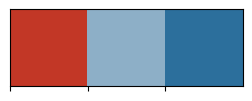

In [4]:
# Paleta divergente: o matiz indica a direção (vermelho = retração, azul = expansão)
# e a intensidade do azul indica a força da expansão.
base = sb.diverging_palette(15, 240, s=85, l=45, n=5, center='light')
PALETA = {
    'Retração Orçamentária': base[0],
    'Média Expansão': base[3],
    'Alta Expansão': base[4],
}
sb.palplot(list(PALETA.values()))## 6. Métricas customizadas com `apply` e paleta de cores

Criei uma função e a apliquei com `apply()` para classificar cada ano pela variação do investimento total em relação ao ano anterior: Retração Orçamentária (menor que 0%), Média Expansão (de 0% até 5%) e Alta Expansão (a partir de 5%). Os limites são escolhas analíticas, e o CSV não informa se os valores são correntes ou deflacionados. O primeiro ano (1996) fica sem categoria por não ter ano anterior.

Usei um gráfico de barras por ano com uma paleta divergente do seaborn (`sb.diverging_palette`): o vermelho indica retração e o azul indica expansão, com o tom mais escuro para a Alta Expansão. Como as categorias têm um ponto de virada natural (o zero), uma paleta divergente deixa a direção do fenômeno visível sem depender da legenda. Uma paleta qualitativa trataria as categorias como equivalentes, e uma sequencial esconderia a diferença entre crescer e encolher.

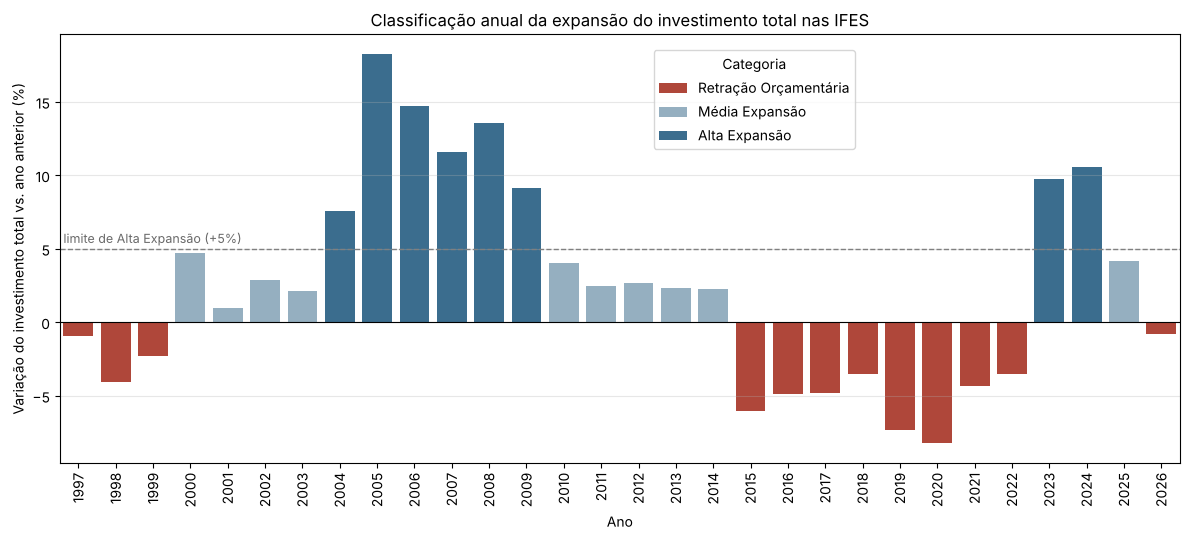

In [5]:
dados = df.dropna(subset=['categoria'])

plt.figure(figsize=(12, 5.5))
ax = sb.barplot(
    data=dados, x='ano', y='var_investimento_pct',
    hue='categoria', hue_order=ORDEM, palette=PALETA, dodge=False
)

ax.axhline(0, color='black', linewidth=0.8)
ax.axhline(5, color='gray', linewidth=1, linestyle='--')
ax.text(-0.4, 5.4, 'limite de Alta Expansão (+5%)', ha='left', fontsize=9, color='dimgray')

ax.set_title('Classificação anual da expansão do investimento total nas IFES')
ax.set_xlabel('Ano')
ax.set_ylabel('Variação do investimento total vs. ano anterior (%)')
ax.tick_params(axis='x', rotation=90)
ax.grid(axis='y', alpha=0.3)
ax.legend(title='Categoria', loc='upper center', bbox_to_anchor=(0.62, 0.98))

plt.tight_layout()
plt.show()

### Decisão de visualização

- **Gráfico de barras por ano** com a variação percentual no eixo y. Barras que saem de uma linha de base em zero mostram bem o sinal: para cima é expansão, para baixo é corte.
- **Paleta divergente** (`sb.diverging_palette`). O vermelho aparece só nos anos de retração e o azul nos de expansão, então a cor já comunica a direção sem consultar a legenda. O tom mais escuro do azul marca a Alta Expansão e o mais claro a Média. Uma paleta qualitativa trataria as três categorias como equivalentes, e uma sequencial esconderia a diferença entre crescer e encolher.
- A categoria segue a ordem natural (retração, média, alta), e a linha tracejada em +5% mostra onde começa a Alta Expansão.
- A cor também ajuda a ver o fenômeno político-econômico: os blocos vermelhos de 1997-1999 e 2015-2022 aparecem como faixas contínuas, e os azuis escuros de 2004-2009 e 2023-2024 como picos de expansão.